<a href="https://colab.research.google.com/github/KAREN-DE-SOUZA/ciencia-de-dados/blob/main/Churn%20Streaming%20_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Passo 1: Montando o Google Drive
Primeiro, vamos conectar o Google Colab ao seu Google Drive para que possamos acessar a pasta com os dados.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Passo 2: Carregando e Explorando o DataFrame
Agora, vamos carregar o arquivo `clientes base.csv` que est no caminho indicado e visualizar as primeiras linhas e o tipo de cada coluna.

In [ ]:
import pandas as pd
import os

def buscar_arquivo(nome_arquivo, caminho_busca='/content/drive/MyDrive'):
    print(f"Buscando por '{nome_arquivo}' no Google Drive...")
    for raiz, diretorios, arquivos in os.walk(caminho_busca):
        for arquivo in arquivos:
            if nome_arquivo.lower() in arquivo.lower():
                caminho_completo = os.path.join(raiz, arquivo)
                print(f"Arquivo encontrado em: {caminho_completo}")
                return caminho_completo
    return None

# Tenta buscar pelas duas variações de nome do arquivo
caminho_encontrado = buscar_arquivo('clientes_base.csv') or buscar_arquivo('clientes base.csv')

if caminho_encontrado:
    try:
        # Carregando o DataFrame
        df = pd.read_csv(caminho_encontrado)

        # Exibindo as primeiras linhas
        print("\n--- Primeiras Linhas do DataFrame ---")
        display(df.head())

        # Exibindo os tipos das colunas
        print("\n--- Tipos das Colunas ---")
        display(df.dtypes)
    except Exception as e:
        print(f"Erro ao ler o arquivo: {e}")
else:
    print("Não conseguimos encontrar o arquivo 'clientes_base.csv' ou 'clientes base.csv' no seu Google Drive.")
    print("Por favor, certifique-se de que o arquivo foi enviado para o Drive correto.")

Buscando por 'clientes_base.csv' no Google Drive...
Arquivo encontrado em: /content/drive/MyDrive/programação assistida/clientes_base.csv

--- Primeiras Linhas do DataFrame ---


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
0,5746,36,BASICO,Anual,19.9,Sudeste,Indicacao,6,2023-04-11,NaN,2024-01-29,2024-01-31,15,276.0,NaN,0
1,4100,48,Padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaN,2024-01-30,2024-01-31,14,394.9,NaN,0
2,4690,48,Premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,2022-10-31,2024-01-31,5,257.0,PREÇO,1
3,3454,46,BASICO,Anual,1990.0,Sul,Google,10,2023-04-02,NaN,2024-01-13,2024-01-31,19,385.0,NaN,0
4,1437,46,Basico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaN,2024-01-16,2024-01-31,11,205.3,NaN,0



--- Tipos das Colunas ---


,0
cliente_id,int64
idade,int64
plano,object
ciclo,object
valor_mensal,float64
regiao,object
canal_aquisicao,object
nps,int64
data_assinatura,object
data_cancelamento,object


### Passo 3: Análise de Valores Únicos e Gráficos de Barra
Vamos analisar a distribuição de frequências para as colunas: `plano`, `ciclo`, `regiao` e `canal_aquisicao` usando tabelas de contagem e gráficos de barra plotados com matplotlib e seaborn.


=== Contagem de Valores Únicos para: PLANO ===


,count
plano,
Basico,708
BASICO,677
básico,677
Padrao,665
Padrão,654
padrão,646
premium,513
Premium,485


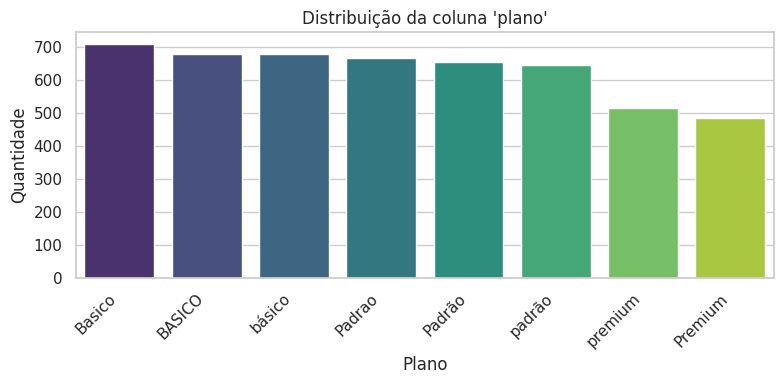


=== Contagem de Valores Únicos para: CICLO ===


,count
ciclo,
Mensal,3794
Anual,1231


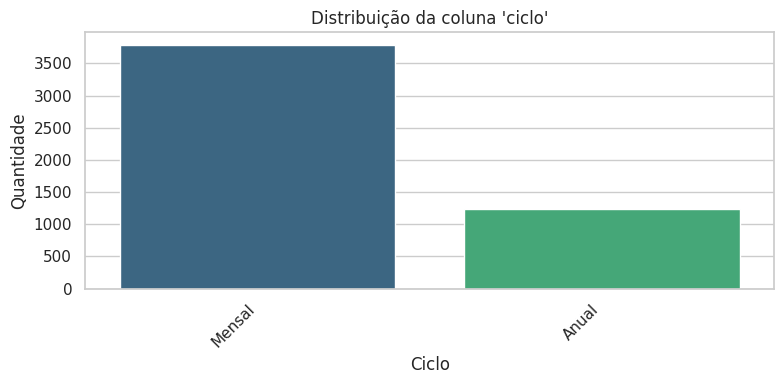


=== Contagem de Valores Únicos para: REGIAO ===


,count
regiao,
Sudeste,2057
Nordeste,964
Sul,938
Centro-Oeste,488
Norte,408
?,170


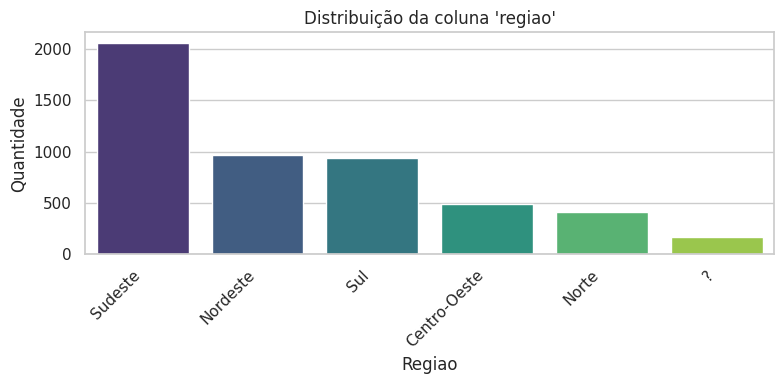


=== Contagem de Valores Únicos para: CANAL_AQUISICAO ===


,count
canal_aquisicao,
Organico,781
orgânico,729
Indicacao,556
IG,529
indicação,526
Instagram,519
instagram,499
Google,452
google,434


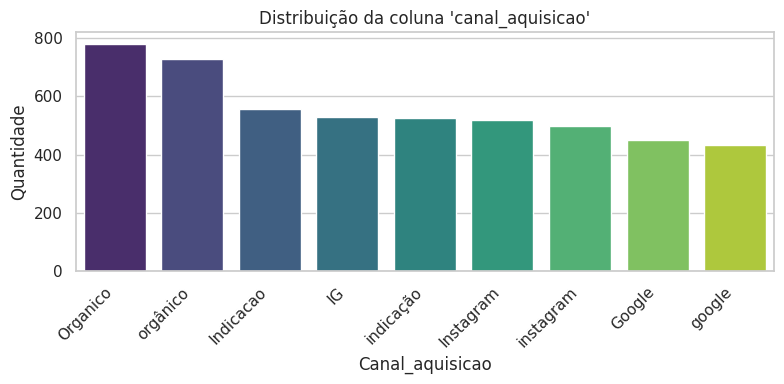

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Lista de colunas para análise
colunas_analise = ['plano', 'ciclo', 'regiao', 'canal_aquisicao']

# Definindo estilo para os gráficos
sns.set_theme(style="whitegrid")

for col in colunas_analise:
    if col in df.columns:
        print(f"\n=== Contagem de Valores Únicos para: {col.upper()} ===")
        contagem = df[col].value_counts(dropna=False)
        display(contagem.to_frame())

        # Criando o gráfico de barras
        plt.figure(figsize=(8, 4))
        sns.barplot(x=contagem.index.astype(str), y=contagem.values, palette='viridis', hue=contagem.index.astype(str), legend=False)
        plt.title(f"Distribuição da coluna '{col}'")
        plt.xlabel(col.capitalize())
        plt.ylabel("Quantidade")
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()
    else:
        print(f"A coluna '{col}' não foi encontrada no DataFrame.")

In [ ]:
# 1. Quantidade de valores nulos nas colunas
print("=== 1. Quantidade de Valores Nulos por Coluna ===")
nulos_por_coluna = df.isnull().sum()
display(nulos_por_coluna.to_frame(name='Total Nulos'))

# 2. Exemplo de DataFrame para quando a coluna regiao é '?'
print("\n=== 2. Exemplo de Clientes com regiao = '?' ===")
if 'regiao' in df.columns:
    df_regiao_interrogacao = df[df['regiao'] == '?']
    print(f"Total de linhas com '?': {len(df_regiao_interrogacao)}")
    display(df_regiao_interrogacao.head())
else:
    print("Coluna 'regiao' não encontrada no DataFrame.")

# 3. Substituições na coluna 'plano'
print("\n=== 3. Padronização da Coluna 'plano' ===")
if 'plano' in df.columns:
    # Recarregamos/redefinimos o mapeamento incluindo todas as variações encontradas
    mapa_planos = {
        'Basico': 'básico',
        'BASICO': 'básico',
        'básico': 'básico',
        'Padrao': 'padrão',
        'Padrão': 'padrão',
        'padrão': 'padrão',
        'Premium': 'premium',
        'premium': 'premium'
    }

    # Aplicando a substituição de forma robusta
    df['plano'] = df['plano'].replace(mapa_planos)

    print("\nValores finais após a padronização completa:")
    print(df['plano'].value_counts(dropna=False))
else:
    print("Coluna 'plano' não encontrada no DataFrame.")

=== 1. Quantidade de Valores Nulos por Coluna ===


,Total Nulos
cliente_id,0
idade,0
plano,0
ciclo,0
valor_mensal,0
regiao,0
canal_aquisicao,0
nps,0
data_assinatura,0
data_cancelamento,3509



=== 2. Exemplo de Clientes com regiao = '?' ===
Total de linhas com '?': 170


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
6,4918,37,básico,Mensal,19.9,?,instagram,4,2023-10-12,2023-12-28,2023-12-09,2024-01-31,5,29.6,problema tecnico,1
10,4356,30,básico,Mensal,19.9,?,Organico,8,2020-12-22,NaN,2024-01-11,2024-01-31,15,900.0,NaN,0
34,1433,56,Padrão,Anual,3490.0,?,orgânico,9,2023-04-14,NaN,2024-01-22,2024-01-31,11,180.4,NaN,0
68,5259,41,padrão,Mensal,34.9,?,google,5,2023-05-03,NaN,2024-01-28,2024-01-31,8,139.9,NaN,0
135,2171,42,Padrão,Mensal,3490.0,?,orgânico,10,2021-04-16,NaN,2024-01-06,2024-01-31,10,505.2,NaN,0



=== 3. Padronização da Coluna 'plano' ===

Valores finais após a padronização completa:
plano
básico     2062
padrão     1965
premium     998
Name: count, dtype: int64


In [ ]:
# Identificando colunas que contêm 'data' no nome
colunas_data = [col for col in df.columns if 'data' in col.lower()]
print(f"Colunas identificadas para conversão: {colunas_data}")

# Convertendo cada uma das colunas para datetime
for col in colunas_data:
    df[col] = pd.to_datetime(df[col], errors='coerce')

# Exibindo os novos tipos de dados das colunas para confirmação
print("\n=== Novos tipos de dados das colunas ===")
display(df[colunas_data].dtypes)

Colunas identificadas para conversão: ['data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao']

=== Novos tipos de dados das colunas ===


,0
data_assinatura,datetime64[ns]
data_cancelamento,datetime64[ns]
data_ultimo_acesso,datetime64[ns]
data_extracao,datetime64[ns]


### Passo 4: Criação do DataFrame de Análise
Vamos criar uma nova coluna para calcular a diferença em dias entre a `data_assinatura` e a `data_extracao`, e em seguida filtrar os registros para gerar o DataFrame `df_analise` com clientes que possuem essa diferença maior ou igual a 220 dias.

In [ ]:
# Verificando se o DataFrame principal 'df' existe no ambiente global
if 'df' not in globals():
    print("AVISO: O DataFrame 'df' não foi encontrado na memória.")
    print("Por favor, certifique-se de executar as células do 'Passo 2' (onde o arquivo é carregado) e 'Passo 3' primeiro.")
else:
    # Calculando a diferença em dias entre data_extracao e data_assinatura
    df['diff_data_assinatura_data_extracao'] = (df['data_extracao'] - df['data_assinatura']).dt.days

    # Criando o df_filtrado como cópia do df principal para consistência
    df_filtrado = df.copy()

    # Criando o df_analise com o filtro especificado (>= 220 dias)
    df_analise = df_filtrado[df_filtrado['diff_data_assinatura_data_extracao'] >= 220].copy()

    # Exibindo informações sobre o novo DataFrame
    print(f"Total de clientes no DataFrame original: {len(df_filtrado)}")
    print(f"Total de clientes no DataFrame de análise (>= 220 dias): {len(df_analise)}")

    # Visualizando as primeiras linhas do df_analise
    display(df_analise.head())

AVISO: O DataFrame 'df' não foi encontrado na memória.
Por favor, certifique-se de executar as células do 'Passo 2' (onde o arquivo é carregado) e 'Passo 3' primeiro.
